In [1]:
import sys
sys.path.insert(0, '../')
import cv2
import matplotlib.pyplot as plt
import numpy as np
from openvino.runtime import Core
import openvino as ov
import ipywidgets as widgets
import torchvision.transforms as transforms
from PIL import Image

In [3]:
#将模型转换为openvino
!mo --input_model ./pf_b_2l2e-05m_35_data.onnx

[ INFO ] Generated IR will be compressed to FP16. If you get lower accuracy, please consider disabling compression explicitly by adding argument --compress_to_fp16=False.
Find more information about compression to FP16 at https://docs.openvino.ai/2023.0/openvino_docs_MO_DG_FP16_Compression.html
[ INFO ] MO command line tool is considered as the legacy conversion API as of OpenVINO 2023.2 release. Please use OpenVINO Model Converter (OVC). OVC represents a lightweight alternative of MO and provides simplified model conversion API. 
Find more information about transition from MO to OVC at https://docs.openvino.ai/2023.2/openvino_docs_OV_Converter_UG_prepare_model_convert_model_MO_OVC_transition.html
[ SUCCESS ] Generated IR version 11 model.
[ SUCCESS ] XML file: /mnt/bb/yc/virtual-tryon-ds/deploy/pf_b_2l2e-05m_35_data.xml
[ SUCCESS ] BIN file: /mnt/bb/yc/virtual-tryon-ds/deploy/pf_b_2l2e-05m_35_data.bin


In [10]:
#由于没有对数据预处理，当直接输入图片时，导致无法得到理想结果，因此对数据进行预处理，预处理的方法需要自己的源码中所使用的方法。
#输入预处理
load_width = 192
input_clothes = Image.open("/mnt/bb/yc/virtual-tryon-ds/data/VITON/VITON/VITON_test/clothes/000010_1.jpg").convert('RGB')
input_person = Image.open("/mnt/bb/yc/virtual-tryon-ds/data/VITON/VITON/VITON_test/test_img/000228_0.jpg").convert('RGB')
plt_clothes = input_clothes #拷贝一份，用于之后绘制图像
plt_person = input_person
transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
        ])
input_clothes = transforms.Resize(load_width, interpolation=2)(input_clothes)
input_person = transforms.Resize(load_width, interpolation=2)(input_person)
input_clothes = transform(input_clothes).unsqueeze(0)  #torch.Size([1,3, 256, 192])
input_person = transform(input_person).unsqueeze(0)#torch.Size([1,3, 256, 192])

input_clothes_np = np.array(input_clothes).astype(np.float32)
input_person_np = np.array(input_person).astype(np.float32)



In [15]:
def result_process(ort_output):
    #对onnx输出处理
    value_range = (np.min(ort_output),np.max(ort_output)) #此处进行归一化
    onnx_output_result = ((ort_output - value_range[0]) / (value_range[1] - value_range[0])) * 255
    onnx_output_result = onnx_output_result.astype(np.uint8)  # 将数据转换为 uint8

    onnx_output_result = np.transpose(onnx_output_result, (2, 3, 1, 0))
    print(onnx_output_result.shape)

    onnx_output_result = np.squeeze(onnx_output_result)
    print(onnx_output_result.shape)
    # onnx_output_result = np.transpose(onnx_output_result, (1, 2, 0))
    return onnx_output_result


In [13]:
#openvino加载onnx模型
onnx_path = "pf_b_2l2e-05m_35_data.onnx"
core = ov.Core()
model_onnx = core.read_model(model=onnx_path)

In [14]:
#选择推理设备
device = widgets.Dropdown(
    options=core.available_devices + ["AUTO"],
    value='AUTO',
    description='Device:',
    disabled=False,
)
device

Dropdown(description='Device:', index=1, options=('CPU', 'AUTO'), value='AUTO')

In [15]:
# Load model on device
compiled_model_onnx = core.compile_model(model=model_onnx, device_name=device.value)

# Run inference on the input image
res_onnx = compiled_model_onnx([input_person_np,input_clothes_np])[0]

(256, 192, 3, 1)
(256, 192, 3)


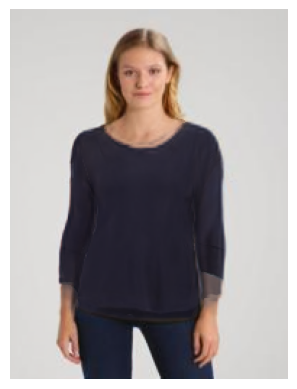

In [16]:
output_result = result_process(res_onnx)
plt.imshow(output_result)
plt.axis("off")
plt.show()


In [17]:
#使用openvino的ir推理
# Load the network in OpenVINO Runtime.
ir_path = "pf_b_2l2e-05m_35_data.xml"
core = ov.Core()
model_ir = core.read_model(model=ir_path)
compiled_model_ir = core.compile_model(model=model_ir, device_name=device.value)

# Get input and output layers.
output_layer_ir = compiled_model_ir.output(0)

# Run inference on the input image.
res_ir = compiled_model_ir([input_person_np,input_clothes_np])[output_layer_ir]

RuntimeError: Exception from src/inference/src/cpp/core.cpp:92:
Exception from src/inference/src/model_reader.cpp:154:
Unable to read the model: pf_b_2l2e-05m_35_data.xml Please check that model format: xml is supported and the model is correct. Available frontends: paddle tf pytorch tflite onnx ir 



(256, 192, 3, 1)
(256, 192, 3)


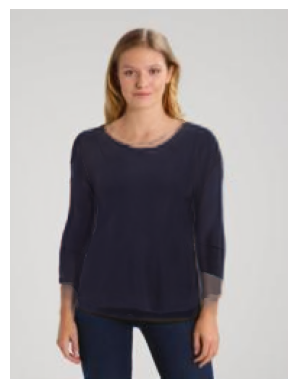

In [33]:
Ir_result = result_process(res_ir)
plt.imshow(Ir_result)
plt.axis("off")
plt.show()

In [35]:
#两模型速度检测
import time
epoch = 30
start_time = time.time()
for i in range(epoch):
    compiled_model_onnx([input_person_np,input_clothes_np])[0]
end_time = time.time()
execution_time = end_time-start_time
print(f"openvino_onnx_model Execution time: {execution_time/epoch:.4f} seconds. FPS:{epoch/execution_time:.4f}")

start_time = time.time()
for i in range(epoch):
    compiled_model_ir([input_person_np,input_clothes_np])[output_layer_ir]
end_time = time.time()
execution_time = end_time-start_time

print(f"openvino_ir_model Execution time: {execution_time/epoch:.4f} seconds. FPS:{epoch/execution_time:.4f}")

openvino_onnx_model Execution time: 0.4693 seconds. FPS:2.1310
openvino_ir_model Execution time: 0.4689 seconds. FPS:2.1326


In [40]:
import os

# 文件路径
onnx_model_path = "./pf_b_2l2e-05m_35_data.onnx"
ir_model_path = "./pf_b_2l2e-05m_35_data.bin"

# 获取文件大小并转换为 MB
onnx_model_size_mb = os.path.getsize(onnx_model_path) / (1024 * 1024)
ir_model_size_mb = os.path.getsize(ir_model_path) / (1024 * 1024)

print(f"ONNX     模型大小：{onnx_model_size_mb:.1f} MB")
print(f"original 模型大小：{ir_model_size_mb:.1f} MB")


ONNX     模型大小：34.8 MB
original 模型大小：17.4 MB


## 与onnxruntime性能比较
| 模型       | 大小   | 时间     |FPS|
|------------|--------|----------|---|
| openvino_onnx_model | 34.8MB | 0.4693ms |2.1310|
| openvino_ir_model  | 17.4MB  | 0.4689ms |2.1326|
| onnx_model | 34.8MB | 0.6217ms |1.4276|
| ori_model  | 34.7MB  | 0.6688ms |1.3532|

## 量化
用更小的精度量化，以获取更快的速度，由于openvino转onnx时默认为float16，已经量化过了，之后采用更小精度量化方法。

In [61]:
#构建一个微调数据集
#需要数据集的输入是人物和衣服，输出是试衣结果
#由于生成数据没有具体的标签数据，因此我使用官网提供的模型得到的输出结果，并从中选择效果较好的图片作为标签数据，以此对量化进行微调。
fine_data = '../data/VITON/fine_data.txt'
unpairs = '../data/VITON/test_unpairs.txt'
save_dir = "../data/VITON/fine_unpairs.txt"
# with open(fine_data,"r") as f:
#     content = f.readlines()
# for i in content:
    

In [63]:
# 读取第一个文件内容并创建映射字典
mapping = {}
with open(unpairs, "r") as file:
    for line in file:
        parts = line.strip().split()  # 按空格分割每一行的内容
        if len(parts) == 2:
            mapping[parts[1]] = parts[0]  # 以_1.jpg文件名为键，以前面的数字文件名为值

# 读取第二个文件内容并查询映射
with open(save_dir,"w") as f:
    with open(fine_data, "r") as file:
        for line in file:
            number = line.strip()+'_1.jpg'
            if number in mapping:
                jpg_file = mapping[number]
                f.write(f"{jpg_file} {number}\n")
                print(f"找到匹配：{number} 对应的文件为 {jpg_file}")
            else:
                print(f"未找到匹配：{number}")


找到匹配：000020_1.jpg 对应的文件为 002511_0.jpg
找到匹配：000028_1.jpg 对应的文件为 004051_0.jpg
找到匹配：000038_1.jpg 对应的文件为 006410_0.jpg
找到匹配：000048_1.jpg 对应的文件为 017021_0.jpg
找到匹配：000057_1.jpg 对应的文件为 005898_0.jpg
找到匹配：000066_1.jpg 对应的文件为 016777_0.jpg
找到匹配：000154_1.jpg 对应的文件为 001092_0.jpg
找到匹配：000174_1.jpg 对应的文件为 012404_0.jpg
找到匹配：000200_1.jpg 对应的文件为 013518_0.jpg
找到匹配：000228_1.jpg 对应的文件为 006486_0.jpg
找到匹配：000240_1.jpg 对应的文件为 002447_0.jpg
找到匹配：000258_1.jpg 对应的文件为 004657_0.jpg
找到匹配：000274_1.jpg 对应的文件为 003621_0.jpg
找到匹配：000303_1.jpg 对应的文件为 018080_0.jpg
找到匹配：000339_1.jpg 对应的文件为 015141_0.jpg
找到匹配：000347_1.jpg 对应的文件为 018608_0.jpg
找到匹配：000356_1.jpg 对应的文件为 016405_0.jpg
找到匹配：000386_1.jpg 对应的文件为 017505_0.jpg
找到匹配：000404_1.jpg 对应的文件为 005336_0.jpg
找到匹配：000417_1.jpg 对应的文件为 007923_0.jpg
找到匹配：000445_1.jpg 对应的文件为 004785_0.jpg
找到匹配：000477_1.jpg 对应的文件为 019037_0.jpg
找到匹配：000501_1.jpg 对应的文件为 004185_0.jpg
找到匹配：000514_1.jpg 对应的文件为 000466_0.jpg
找到匹配：000523_1.jpg 对应的文件为 007974_0.jpg
找到匹配：000542_1.jpg 对应的文件为 013106_0.jpg
找到匹配：000568_

In [4]:

import argparse
from os import path as osp
import random
from PIL import Image, ImageDraw
import torch
from torch.utils import data
from torchvision import transforms
import nncf
import openvino.runtime as ov
import torch
from torchvision import datasets, transforms

import numpy as np

INFO:nncf:NNCF initialized successfully. Supported frameworks detected: torch, onnx, openvino


In [5]:
def get_opt(opt=None):
    parser = argparse.ArgumentParser()
    parser.add_argument('--name', type=str,default="TEST_PAIR")
    parser.add_argument('-j', '--workers', type=int, default=4)
    parser.add_argument('--load_height', type=int, default=256)
    parser.add_argument('--load_width', type=int, default = 192)
    parser.add_argument('--shuffle', action='store_true')
    parser.add_argument('--dataset_imgpath', type=str, default='../data/VITON/VITON/VITON_test')
    parser.add_argument('--dataset_list', type=str, default=r'../data/VITON/fine_unpairs.txt')
    parser.add_argument('--test_out', type=str, default='../results/TEST_PAIR/original_model')
    parser.add_argument('-f', type=str, default="读取额外的参数")
    opt = parser.parse_args(args=[])
    return opt

In [6]:
class VITONDataset(data.Dataset):
    def __init__(self, opt):
        super(VITONDataset, self).__init__()
        self.opt = opt
        self.load_height = opt.load_height
        self.load_width = opt.load_width
        self.data_path = opt.dataset_imgpath
        self.transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
        ])
        img_names = []
        c_names = []

        with open(opt.dataset_list, 'r') as f:
            for line in f.readlines():
                img_name, c_name = line.strip().split()
                img_names.append(img_name)
                c_names.append(c_name)
        self.img_names = img_names
        self.c_names = c_names


    def __getitem__(self, index):
        img_name = self.img_names[index]
        c_name = self.c_names[index]


        # load person image
        img = Image.open(osp.join(self.data_path, 'test_img', img_name))
        img = transforms.Resize(self.load_width, interpolation=2)(img)
        img = self.transform(img)
        #load clothes image
        c = Image.open(osp.join(self.data_path, 'clothes', c_name))
        c = transforms.Resize(self.load_width, interpolation=2)(c)
        c = self.transform(c)

        #load test output
        targe = Image.open(osp.join(opt.test_out, img_name))
        targe = transforms.Resize(self.load_width, interpolation=2)(targe)
        targe = self.transform(targe)
        
        img = torch.flip(img,[2])
        c = torch.flip(c,[2])
        # result = {
        # 'img_name': img_name,
        # 'c_name': c_name,
        # 'img': torch.flip(img,[2]),
        # 'cloth': torch.flip(c,[2]),
        # "targe":targe
        # }
        

        return ((img,c),targe)
    def __len__(self):
        return len(self.img_names)


In [7]:
opt = get_opt()


In [8]:
test_dataset = VITONDataset(opt)
dataset_loader  = data.DataLoader(test_dataset, batch_size=1)

In [9]:
model = ov.Core().read_model("pf_b_2l2e-05m_35_data.xml")
# Step 1: Initialize transformation function
def transform_fn(data_item):
    images, _ = data_item
    return images

# Step 2: Initialize NNCF Dataset
calibration_dataset = nncf.Dataset(dataset_loader, transform_fn)
# Step 3: Run the quantization pipeline
quantized_model = nncf.quantize(model, calibration_dataset)

Output()

Output()

In [12]:
# compile the model to transform quantized operations to int8
model_int8 = ov.compile_model(quantized_model)

input_fp32 =  [input_person_np,input_clothes_np]# FP32 model input
res = model_int8(input_fp32)

# save the model
ov.save_model(quantized_model, "quantized_int8_model.xml")

In [22]:
int8_output = result_process(res)
plt.imshow(int8_output)
plt.show()
# print(res)
# print(type(res))
# print(res.shape)

TypeError: unsupported operand type(s) for -: 'OVDict' and 'openvino._pyopenvino.ConstOutput'

In [29]:
#使用openvino的ir推理
# Load the network in OpenVINO Runtime.
int8_ir_path = "quantized_int8_model.xml"
core = ov.Core()
int8_model_ir = core.read_model(model=int8_ir_path)
compiled_model_int8 = core.compile_model(model=int8_model_ir)

# Get input and output layers.
output_layer_ir = compiled_model_int8.output(0)

# Run inference on the input image.
int8_res_ir = compiled_model_int8([input_person_np,input_clothes_np])[output_layer_ir]

(256, 192, 3, 1)
(256, 192, 3)


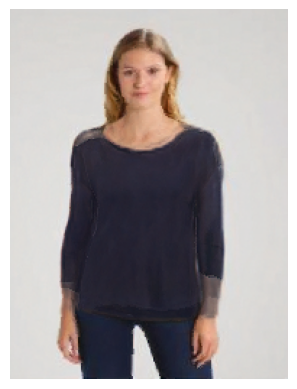

In [30]:
int8_output = result_process(int8_res_ir)
plt.imshow(int8_output)
plt.axis("off")
plt.show()


In [31]:
#推理速度
import time
epoch = 30
start_time = time.time()
for i in range(epoch):
    compiled_model_int8([input_person_np,input_clothes_np])[0]
end_time = time.time()
execution_time = end_time-start_time
print(f"compiled_model_int8 Execution time: {execution_time/epoch:.4f} seconds. FPS:{epoch/execution_time:.4f}")


compiled_model_int8 Execution time: 0.3482 seconds. FPS:2.8722


In [35]:
import os

# 文件路径
int8_model_path = "./quantized_int8_model.bin"

# 获取文件大小并转换为 MB
int8_model_size_mb = os.path.getsize(int8_model_path) / (1024 * 1024)

print(f"int8_model     模型大小：{int8_model_size_mb:.2f} MB")



int8_model     模型大小：8.73 MB


## 量化后的int8与其他模型性能比较
| 模型       | 大小   | 时间     |FPS|
|------------|--------|----------|---|
| openvino_onnx_model | 34.8MB | 0.4693ms |2.1310|
| openvino_ir_model  | 17.4MB  | 0.4689ms |2.1326|
| onnx_model | 34.8MB | 0.6217ms |1.4276|
| ori_model  | 34.7MB  | 0.6688ms |1.3532|
| int8_model| 8.73 MB|0.3482ms |2.8722|

In [ ]:
#试衣效果对比
